### San Francisco Airport Clustering Model

<img src="https://assets.simpleviewinc.com/simpleview/image/upload/crm/sanmateoca/SFO_Arch_4_17_2018_1063-30-06b9617a5056a36_06b9639f-5056-a36a-0bed1338babc4328.jpg" width=900>

## Introduction

This project analyzes passenger and airline data from **San Francisco International Airport (SFO)** using **K-Means Clustering**.

The goal is to identify patterns in passenger traffic and airline activity through three clustering approaches.

The project includes data preprocessing, exploratory data analysis (EDA), feature scaling, clustering, and model evaluation using the **Elbow Method** and **Silhouette Score**.

**Technologies:** Python, Pandas, NumPy, Scikit-learn, Matplotlib, and Seaborn.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from pathlib import Path
from sklearn import datasets
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from yellowbrick.cluster import KElbowVisualizer
from scipy.cluster.hierarchy import dendrogram,linkage
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns',100)

# Read data

In [2]:
df=pd.read_csv('air-traffic-passenger-statistics.csv')

### EDA

In [3]:
df.head()

,Activity Period,Operating Airline,Operating Airline IATA Code,Published Airline,Published Airline IATA Code,GEO Summary,GEO Region,Activity Type Code,Price Category Code,Terminal,Boarding Area,Passenger Count
0,200507,ATA Airlines,TZ,ATA Airlines,TZ,Domestic,US,Deplaned,Low Fare,Terminal 1,B,27271
1,200507,ATA Airlines,TZ,ATA Airlines,TZ,Domestic,US,Enplaned,Low Fare,Terminal 1,B,29131
2,200507,ATA Airlines,TZ,ATA Airlines,TZ,Domestic,US,Thru / Transit,Low Fare,Terminal 1,B,5415
3,200507,Air Canada,AC,Air Canada,AC,International,Canada,Deplaned,Other,Terminal 1,B,35156
4,200507,Air Canada,AC,Air Canada,AC,International,Canada,Enplaned,Other,Terminal 1,B,34090


In [4]:
df.tail()

,Activity Period,Operating Airline,Operating Airline IATA Code,Published Airline,Published Airline IATA Code,GEO Summary,GEO Region,Activity Type Code,Price Category Code,Terminal,Boarding Area,Passenger Count
18880,201806,WOW Air,WW,WOW Air,WW,International,Europe,Enplaned,Other,International,G,50
18881,201806,WestJet Airlines,WS,WestJet Airlines,WS,International,Canada,Deplaned,Other,International,A,10868
18882,201806,WestJet Airlines,WS,WestJet Airlines,WS,International,Canada,Enplaned,Other,International,A,11664
18883,201806,XL Airways France,SE,XL Airways France,SE,International,Europe,Deplaned,Other,International,A,804
18884,201806,XL Airways France,SE,XL Airways France,SE,International,Europe,Enplaned,Other,International,A,1243


In [5]:
df.shape

(18885, 12)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18885 entries, 0 to 18884
Data columns (total 12 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   Activity Period              18885 non-null  int64 
 1   Operating Airline            18885 non-null  object
 2   Operating Airline IATA Code  18822 non-null  object
 3   Published Airline            18885 non-null  object
 4   Published Airline IATA Code  18822 non-null  object
 5   GEO Summary                  18885 non-null  object
 6   GEO Region                   18885 non-null  object
 7   Activity Type Code           18885 non-null  object
 8   Price Category Code          18885 non-null  object
 9   Terminal                     18885 non-null  object
 10  Boarding Area                18885 non-null  object
 11  Passenger Count              18885 non-null  int64 
dtypes: int64(2), object(10)
memory usage: 1.7+ MB


In [7]:
df.isnull().sum()

Activity Period                 0
Operating Airline               0
Operating Airline IATA Code    63
Published Airline               0
Published Airline IATA Code    63
GEO Summary                     0
GEO Region                      0
Activity Type Code              0
Price Category Code             0
Terminal                        0
Boarding Area                   0
Passenger Count                 0
dtype: int64

### Feature Engineering

In [8]:
df[df['Operating Airline IATA Code'] != df['Published Airline IATA Code']]

,Activity Period,Operating Airline,Operating Airline IATA Code,Published Airline,Published Airline IATA Code,GEO Summary,GEO Region,Activity Type Code,Price Category Code,Terminal,Boarding Area,Passenger Count
25,200507,American Eagle Airlines,MQ,American Airlines,AA,Domestic,US,Deplaned,Other,Terminal 3,E,5493
26,200507,American Eagle Airlines,MQ,American Airlines,AA,Domestic,US,Enplaned,Other,Terminal 3,E,5213
29,200507,Atlantic Southeast Airlines,EV,Delta Air Lines,DL,Domestic,US,Deplaned,Other,Terminal 1,C,1552
30,200507,Atlantic Southeast Airlines,EV,Delta Air Lines,DL,Domestic,US,Enplaned,Other,Terminal 1,C,1484
47,200507,Horizon Air,QX,Alaska Airlines,AS,Domestic,US,Deplaned,Other,Terminal 1,B,5284
...,...,...,...,...,...,...,...,...,...,...,...,...
18827,201806,SkyWest Airlines,OO,United Airlines,UA,Domestic,US,Deplaned,Other,Terminal 3,F,149286
18828,201806,SkyWest Airlines,OO,United Airlines,UA,Domestic,US,Enplaned,Other,Terminal 3,F,153973
18829,201806,SkyWest Airlines,OO,United Airlines,UA,International,Canada,Deplaned,Other,International,G,1284
18830,201806,SkyWest Airlines,OO,United Airlines,UA,International,Canada,Deplaned,Other,Terminal 3,F,2619


In [9]:
(df['Operating Airline IATA Code'] != df['Published Airline IATA Code']).sum()

np.int64(2122)

In [10]:
df[df['Operating Airline'] == 'Swissport USA']

,Activity Period,Operating Airline,Operating Airline IATA Code,Published Airline,Published Airline IATA Code,GEO Summary,GEO Region,Activity Type Code,Price Category Code,Terminal,Boarding Area,Passenger Count
9484,201204,Swissport USA,NaN,Swissport USA,NaN,International,Europe,Deplaned,Other,International,A,167
9485,201204,Swissport USA,NaN,Swissport USA,NaN,International,Europe,Enplaned,Other,International,A,183
9486,201204,Swissport USA,NaN,Swissport USA,NaN,International,Europe,Thru / Transit,Other,International,A,93
10861,201304,Swissport USA,NaN,Swissport USA,NaN,Domestic,US,Deplaned,Other,International,A,399
10862,201304,Swissport USA,NaN,Swissport USA,NaN,Domestic,US,Enplaned,Other,International,A,560
10977,201305,Swissport USA,NaN,Swissport USA,NaN,International,Europe,Deplaned,Other,International,A,300
10978,201305,Swissport USA,NaN,Swissport USA,NaN,International,Europe,Enplaned,Other,International,A,300
11210,201307,Swissport USA,NaN,Swissport USA,NaN,International,Europe,Deplaned,Other,International,A,276
11211,201307,Swissport USA,NaN,Swissport USA,NaN,International,Europe,Enplaned,Other,International,A,276
11781,201312,Swissport USA,NaN,Swissport USA,NaN,Domestic,US,Deplaned,Other,International,A,214


In [11]:
df[df.isna().any(axis=1)]

,Activity Period,Operating Airline,Operating Airline IATA Code,Published Airline,Published Airline IATA Code,GEO Summary,GEO Region,Activity Type Code,Price Category Code,Terminal,Boarding Area,Passenger Count
148,200508,Boeing Company,NaN,Boeing Company,NaN,Domestic,US,Deplaned,Other,Other,Other,18
6809,201005,Servisair,NaN,Servisair,NaN,Domestic,US,Deplaned,Low Fare,International,G,73
6810,201005,Servisair,NaN,Servisair,NaN,Domestic,US,Enplaned,Low Fare,International,G,73
6920,201006,Pacific Aviation,NaN,Pacific Aviation,NaN,International,Europe,Deplaned,Other,International,A,160
6921,201006,Pacific Aviation,NaN,Pacific Aviation,NaN,International,Europe,Enplaned,Other,International,A,160
...,...,...,...,...,...,...,...,...,...,...,...,...
16868,201705,Trego Dugan Aviation,NaN,Trego Dugan Aviation,NaN,Domestic,US,Deplaned,Low Fare,International,A,108
16869,201705,Trego Dugan Aviation,NaN,Trego Dugan Aviation,NaN,Domestic,US,Enplaned,Low Fare,International,A,304
17631,201710,Swissport USA,NaN,Swissport USA,NaN,International,Europe,Deplaned,Other,International,A,73
17632,201710,Swissport USA,NaN,Swissport USA,NaN,International,Europe,Enplaned,Other,International,A,73


This Airlines are not passenger airlines.

In [12]:
df=df[df['Operating Airline']!='Boeing Company']

In [13]:
df=df[df['Operating Airline']!='Servisair']

In [14]:
df=df[df['Operating Airline']!='Pacific Aviation']

In [15]:
df=df[df['Operating Airline']!='Trego Dugan Aviation']

In [16]:
df=df[df['Operating Airline']!='Swissport USA']

In [17]:
df.isnull().sum()

Activity Period                0
Operating Airline              0
Operating Airline IATA Code    0
Published Airline              0
Published Airline IATA Code    0
GEO Summary                    0
GEO Region                     0
Activity Type Code             0
Price Category Code            0
Terminal                       0
Boarding Area                  0
Passenger Count                0
dtype: int64

In [18]:
df['Operating Airline'].value_counts()

Operating Airline
United Airlines - Pre 07/01/2013    2154
United Airlines                     1653
SkyWest Airlines                    1212
Alaska Airlines                      891
Virgin America                       462
                                    ... 
World Airways                          3
Xtra Airways                           2
Evergreen International Airlines       2
Atlas Air, Inc                         2
Icelandair EHF                         2
Name: count, Length: 84, dtype: int64

In [19]:
df["Operating Airline"]=df["Operating Airline"].replace({"United Airlines - Pre 07/01/2013": "United Airlines"})

In [20]:
df["Published Airline"] = df["Published Airline"].replace({"United Airlines - Pre 07/01/2013": "United Airlines"})

In [21]:
df['GEO Summary'].value_counts()

GEO Summary
International    11884
Domestic          6938
Name: count, dtype: int64

In [22]:
df['GEO Region'].value_counts()

GEO Region
US                     6938
Asia                   4072
Europe                 2786
Canada                 1794
Mexico                 1455
Australia / Oceania     951
Central America         381
Middle East             354
South America            91
Name: count, dtype: int64

In [23]:
df['Activity Type Code'].value_counts()

Activity Type Code
Enplaned          8901
Deplaned          8876
Thru / Transit    1045
Name: count, dtype: int64

In [24]:
df['Price Category Code'].value_counts()

Price Category Code
Other       16496
Low Fare     2326
Name: count, dtype: int64

In [25]:
df['Terminal'].value_counts()

Terminal
International    11901
Terminal 1        3610
Terminal 3        2699
Terminal 2         586
Other               26
Name: count, dtype: int64

In [26]:
d={'Other':0,'Low Fare':1}

In [27]:
df['Price Category Code']=df['Price Category Code'].map(d)

In [28]:
df['Price Category Code'].value_counts()

Price Category Code
0    16496
1     2326
Name: count, dtype: int64

In [29]:
d={'Domestic':0,'International':1}

In [30]:
df['GEO Summary']=df['GEO Summary'].map(d)

In [31]:
df['GEO Summary'].value_counts()

GEO Summary
1    11884
0     6938
Name: count, dtype: int64

In [32]:
# flights per year and month
df['Year']=df['Activity Period']//100
df['Month']=df['Activity Period']%100

In [33]:
df.head()

,Activity Period,Operating Airline,Operating Airline IATA Code,Published Airline,Published Airline IATA Code,GEO Summary,GEO Region,Activity Type Code,Price Category Code,Terminal,Boarding Area,Passenger Count,Year,Month
0,200507,ATA Airlines,TZ,ATA Airlines,TZ,0,US,Deplaned,1,Terminal 1,B,27271,2005,7
1,200507,ATA Airlines,TZ,ATA Airlines,TZ,0,US,Enplaned,1,Terminal 1,B,29131,2005,7
2,200507,ATA Airlines,TZ,ATA Airlines,TZ,0,US,Thru / Transit,1,Terminal 1,B,5415,2005,7
3,200507,Air Canada,AC,Air Canada,AC,1,Canada,Deplaned,0,Terminal 1,B,35156,2005,7
4,200507,Air Canada,AC,Air Canada,AC,1,Canada,Enplaned,0,Terminal 1,B,34090,2005,7


In [34]:
year_counts=df['Year'].value_counts().sort_index()

In [35]:
month_passengers=df.groupby('Month')['Passenger Count'].mean()

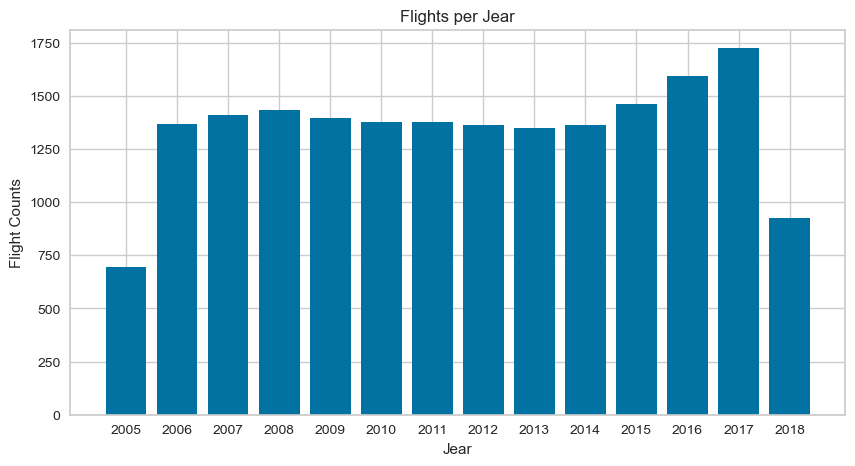

In [36]:
plt.figure(figsize=(10,5))
plt.bar(year_counts.index, year_counts.values)
plt.xlabel("Jear")
plt.ylabel("Flight Counts")
plt.title("Flights per Jear")
plt.xticks(year_counts.index)
plt.show()

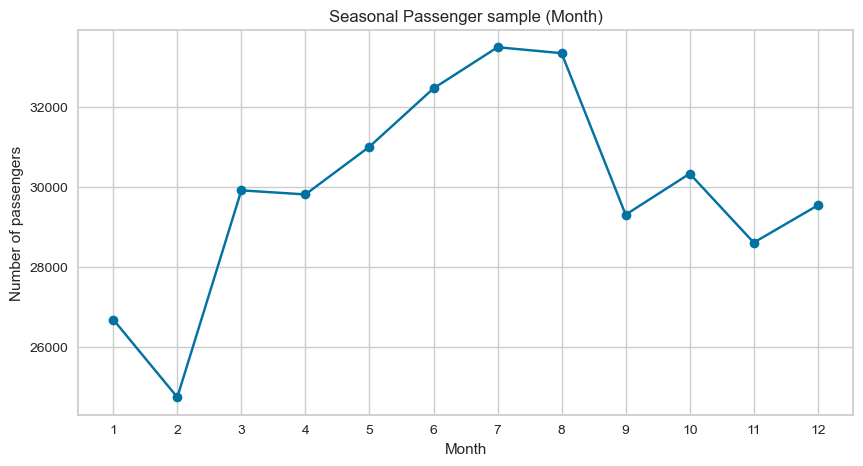

In [37]:
plt.figure(figsize=(10,5))
plt.plot(month_passengers.index, month_passengers.values, marker='o')
plt.xlabel("Month")
plt.ylabel("Number of passengers")
plt.title("Seasonal Passenger sample (Month)")
plt.xticks(range(1,13))
plt.grid(True)
plt.show()

In [38]:
pivot=df.pivot_table(index='Year',columns='Month',values='Passenger Count',aggfunc='sum')

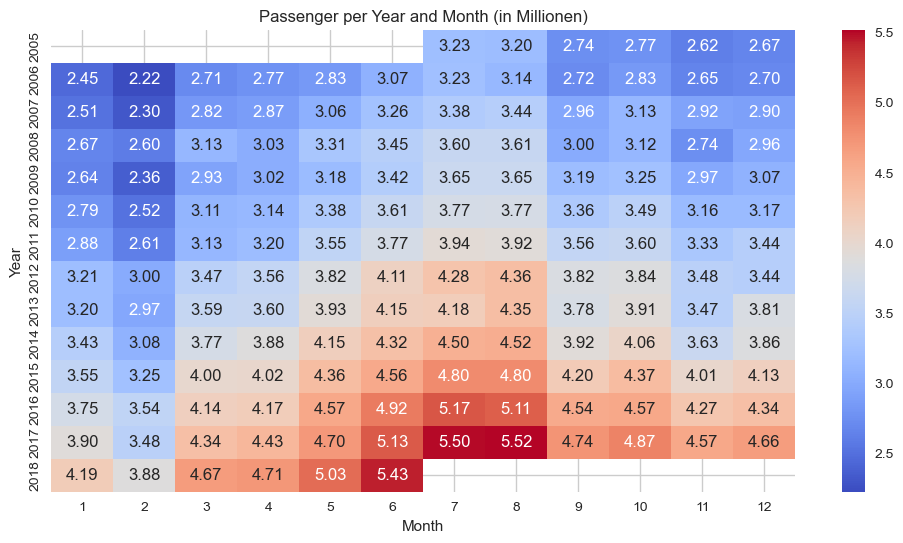

In [39]:
pivot_million = pivot / 1_000_000

plt.figure(figsize=(12,6))
sns.heatmap(
    pivot_million,
    cmap='coolwarm',
    annot=True,
    fmt='.2f'
)
plt.title("Passenger per Year and Month (in Millionen)")
plt.show()

### Passenger Traffic Heatmap

This heatmap shows monthly passenger volumes across different years, helping identify seasonal patterns and changes in airport activity.

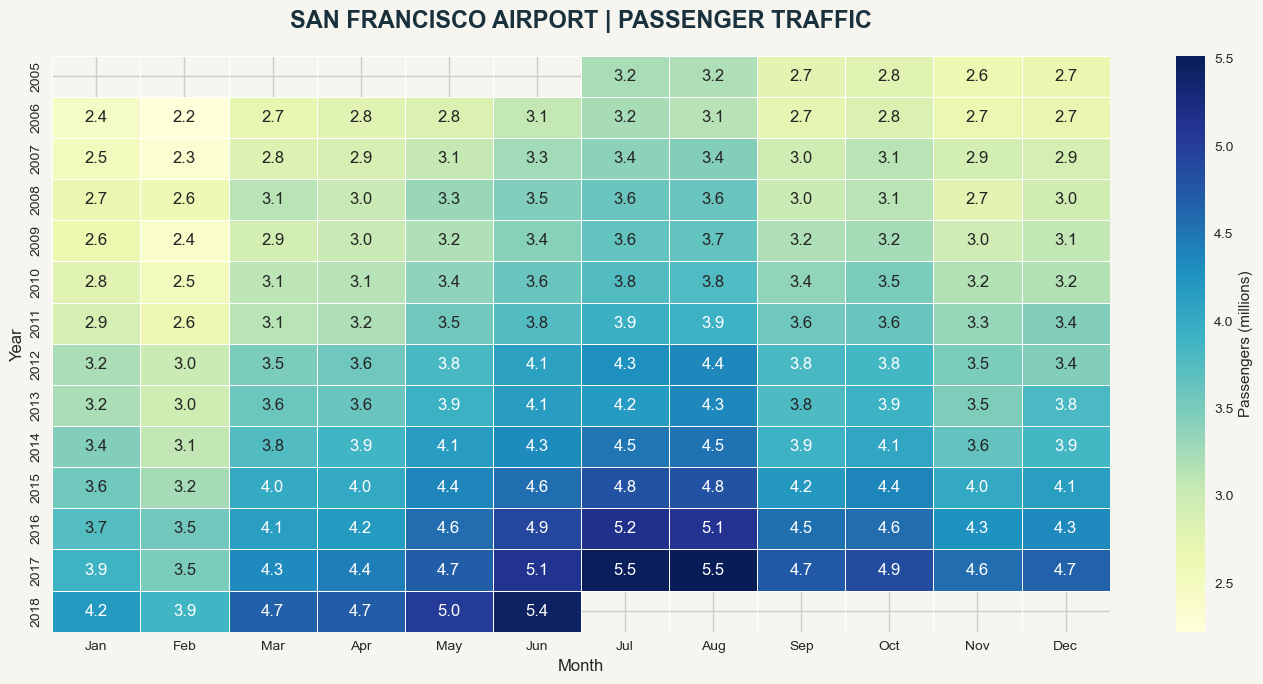

In [40]:
Path('images').mkdir(exist_ok=True)

heatmap_data = pivot / 1_000_000

fig, ax = plt.subplots(figsize=(14, 7), facecolor='#F7F5F0')
ax.set_facecolor('#F7F5F0')

sns.heatmap(
    heatmap_data,
    cmap='YlGnBu',
    annot=True,
    fmt='.1f',
    linewidths=0.6,
    linecolor='white',
    cbar_kws={'label': 'Passengers (millions)'},
    ax=ax
)

ax.set_title(
    'SAN FRANCISCO AIRPORT | PASSENGER TRAFFIC',
    fontsize=17,
    fontweight='bold',
    color='#19313D',
    pad=20
)
ax.set_xlabel('Month', fontsize=12)
ax.set_ylabel('Year', fontsize=12)
ax.set_xticklabels(
    ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
     'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'],
    rotation=0
)

plt.tight_layout()
plt.savefig(
    'images/passenger_heatmap.png',
    dpi=300,
    bbox_inches='tight',
    facecolor=fig.get_facecolor()
)
plt.show()

In [41]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 18822 entries, 0 to 18884
Data columns (total 14 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   Activity Period              18822 non-null  int64 
 1   Operating Airline            18822 non-null  object
 2   Operating Airline IATA Code  18822 non-null  object
 3   Published Airline            18822 non-null  object
 4   Published Airline IATA Code  18822 non-null  object
 5   GEO Summary                  18822 non-null  int64 
 6   GEO Region                   18822 non-null  object
 7   Activity Type Code           18822 non-null  object
 8   Price Category Code          18822 non-null  int64 
 9   Terminal                     18822 non-null  object
 10  Boarding Area                18822 non-null  object
 11  Passenger Count              18822 non-null  int64 
 12  Year                         18822 non-null  int64 
 13  Month                        18822 n

In [42]:
x1=df[['GEO Summary','GEO Region','Activity Type Code','Price Category Code','Passenger Count']]

In [43]:
x1=pd.get_dummies(x1,drop_first=True)

In [44]:
x1.head()

,GEO Summary,Price Category Code,Passenger Count,GEO Region_Australia / Oceania,GEO Region_Canada,GEO Region_Central America,GEO Region_Europe,GEO Region_Mexico,GEO Region_Middle East,GEO Region_South America,GEO Region_US,Activity Type Code_Enplaned,Activity Type Code_Thru / Transit
0,0,1,27271,False,False,False,False,False,False,False,True,False,False
1,0,1,29131,False,False,False,False,False,False,False,True,True,False
2,0,1,5415,False,False,False,False,False,False,False,True,False,True
3,1,0,35156,False,True,False,False,False,False,False,False,False,False
4,1,0,34090,False,True,False,False,False,False,False,False,True,False


### Modelling

In [45]:
# Instantiate the clustering model and visualizer
km = KMeans(random_state=42)
visualizer = KElbowVisualizer(km, k=(2,10))

  File "C:\Users\enesy\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\enesy\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\enesy\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\enesy\anaconda3\Lib\subprocess.

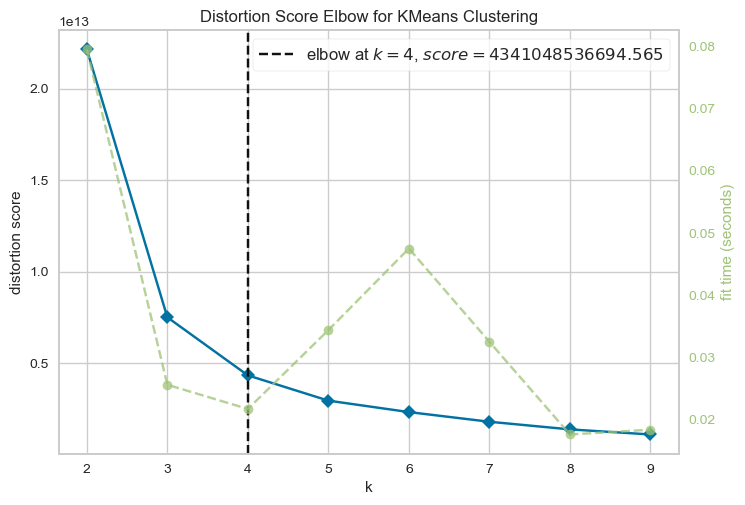

In [46]:
visualizer.fit(x1) # Fit the data to the visualizer
visualizer.show(); # Finalize and render the figure

In [47]:
x1=StandardScaler().fit_transform(x1)

In [48]:
model=KMeans(4)

In [49]:
model=model.fit(x1)

In [50]:
tahmin=model.predict(x1)

In [51]:
tahmin

array([2, 2, 2, ..., 3, 1, 3], dtype=int32)

In [52]:
df['Cluster']=tahmin

In [53]:
df['Cluster'].value_counts()

Cluster
1    6061
3    5692
0    4904
2    2165
Name: count, dtype: int64

In [54]:
df.head()

,Activity Period,Operating Airline,Operating Airline IATA Code,Published Airline,Published Airline IATA Code,GEO Summary,GEO Region,Activity Type Code,Price Category Code,Terminal,Boarding Area,Passenger Count,Year,Month,Cluster
0,200507,ATA Airlines,TZ,ATA Airlines,TZ,0,US,Deplaned,1,Terminal 1,B,27271,2005,7,2
1,200507,ATA Airlines,TZ,ATA Airlines,TZ,0,US,Enplaned,1,Terminal 1,B,29131,2005,7,2
2,200507,ATA Airlines,TZ,ATA Airlines,TZ,0,US,Thru / Transit,1,Terminal 1,B,5415,2005,7,2
3,200507,Air Canada,AC,Air Canada,AC,1,Canada,Deplaned,0,Terminal 1,B,35156,2005,7,1
4,200507,Air Canada,AC,Air Canada,AC,1,Canada,Enplaned,0,Terminal 1,B,34090,2005,7,3


In [55]:
silhouette_score(x1,tahmin)

0.2622218492035883

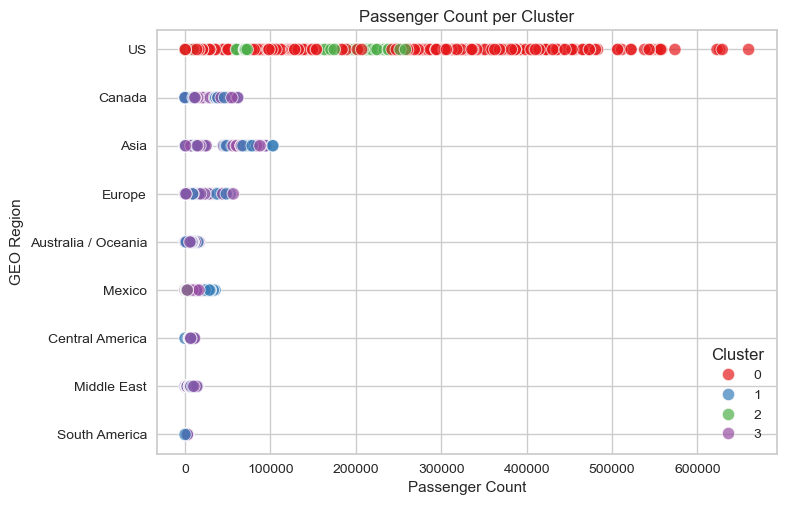

In [56]:
sns.scatterplot(data=df,x='Passenger Count',y='GEO Region',hue='Cluster',palette='Set1',s=80,alpha=0.7)
plt.title("Passenger Count per Cluster")
plt.show()

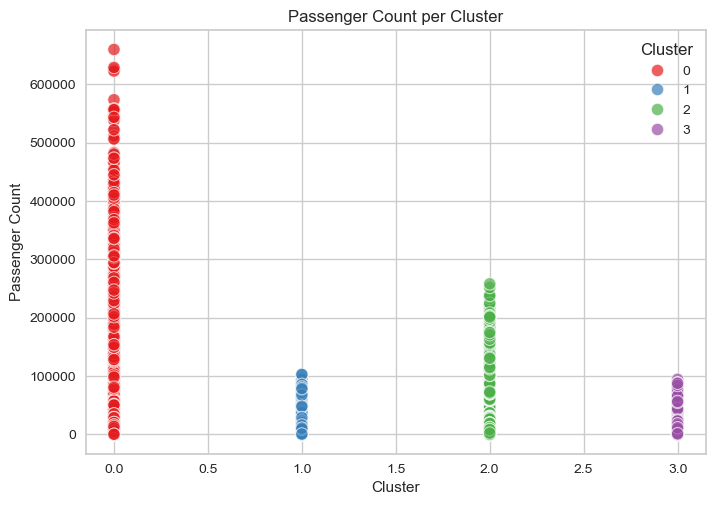

In [57]:
sns.scatterplot(data=df,x='Cluster',y='Passenger Count',hue='Cluster',palette='Set1',s=80,alpha=0.7)
plt.title("Passenger Count per Cluster")
plt.show()

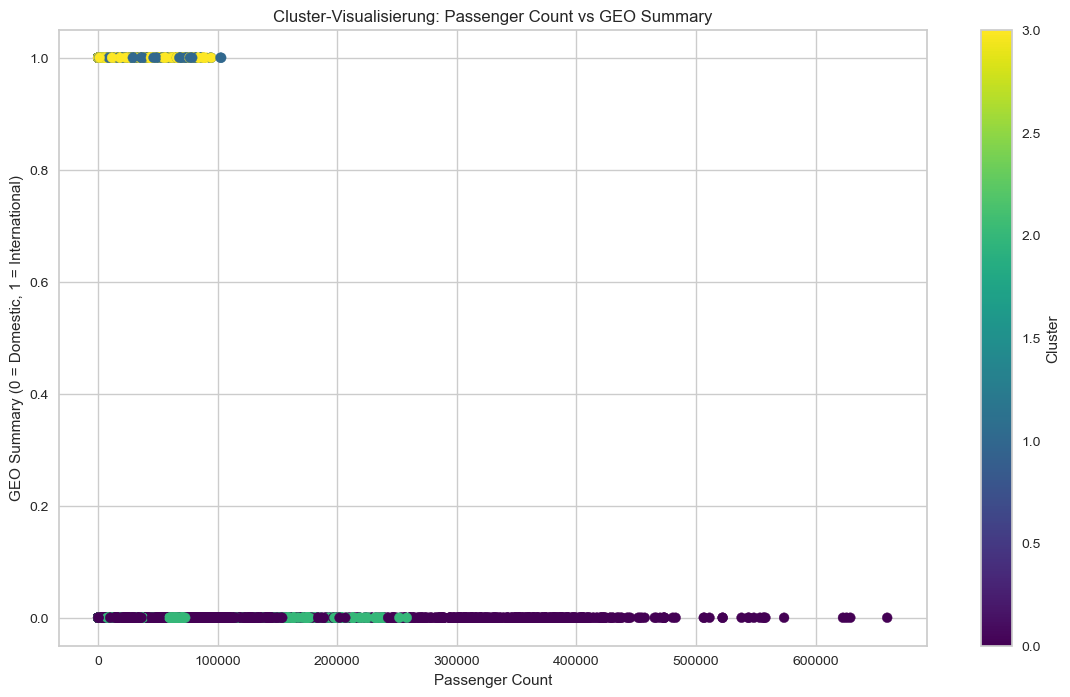

In [58]:
plt.figure(figsize=(14,8))

plt.scatter(
    df['Passenger Count'],
    df['GEO Summary'],
    c=df['Cluster'],
    cmap='viridis',
    s=50
)

plt.xlabel("Passenger Count")
plt.ylabel("GEO Summary (0 = Domestic, 1 = International)")
plt.title("Cluster-Visualisierung: Passenger Count vs GEO Summary")

plt.colorbar(label="Cluster")
plt.show()

### K-Means Clustering Visualization (PCA)

PCA reduces the feature space to two dimensions for visualization. Colors represent the four clusters identified by K-Means.

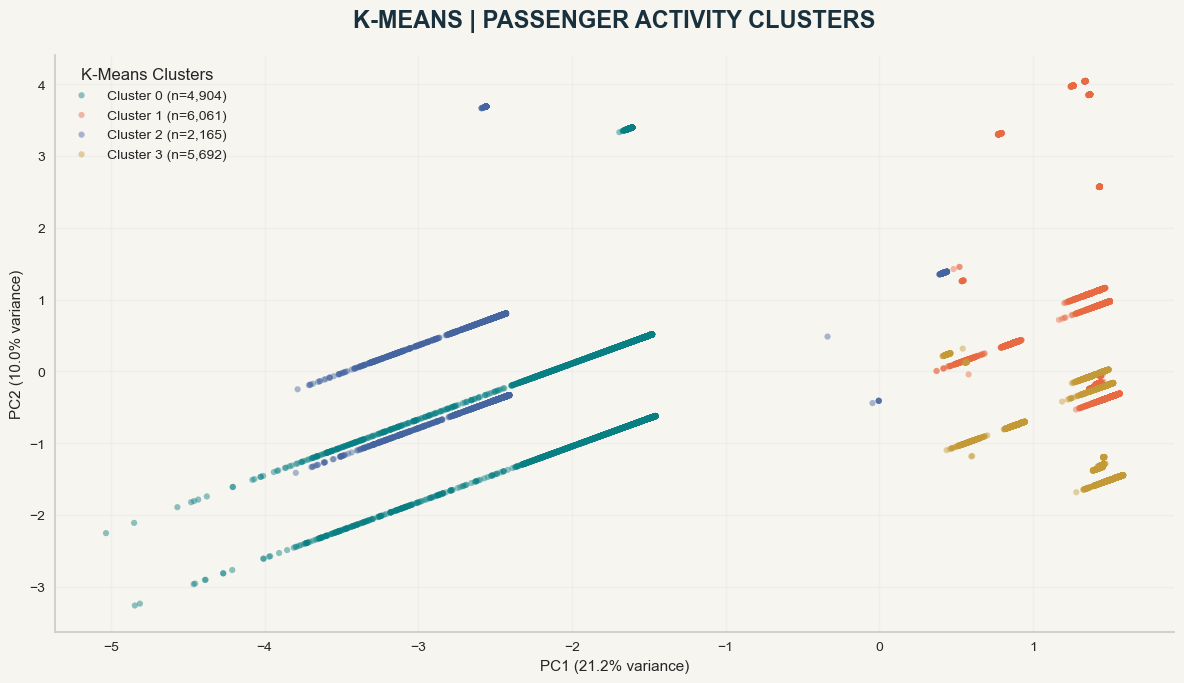

In [59]:
pca = PCA(n_components=2)
x1_pca = pca.fit_transform(x1)

colors = ['#087F83', '#E86A43', '#4565A0', '#C49A36']

fig, ax = plt.subplots(figsize=(12, 7), facecolor='#F7F5F0')
ax.set_facecolor('#F7F5F0')

for cluster in sorted(np.unique(tahmin)):
    mask = tahmin == cluster

    ax.scatter(
        x1_pca[mask, 0],
        x1_pca[mask, 1],
        s=20,
        alpha=0.45,
        color=colors[int(cluster)],
        label=f'Cluster {cluster} (n={mask.sum():,})',
        edgecolors='none'
    )

ax.set_title(
    'K-MEANS | PASSENGER ACTIVITY CLUSTERS',
    fontsize=17,
    fontweight='bold',
    color='#19313D',
    pad=20
)

ax.set_xlabel(
    f'PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)'
)
ax.set_ylabel(
    f'PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)'
)

ax.legend(title='K-Means Clusters', frameon=False)
ax.grid(alpha=0.15)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig(
    'images/kmeans_pca_clusters.png',
    dpi=300,
    bbox_inches='tight',
    facecolor=fig.get_facecolor()
)
plt.show()

In [60]:
data=linkage(x1,method='ward', metric='euclidean')

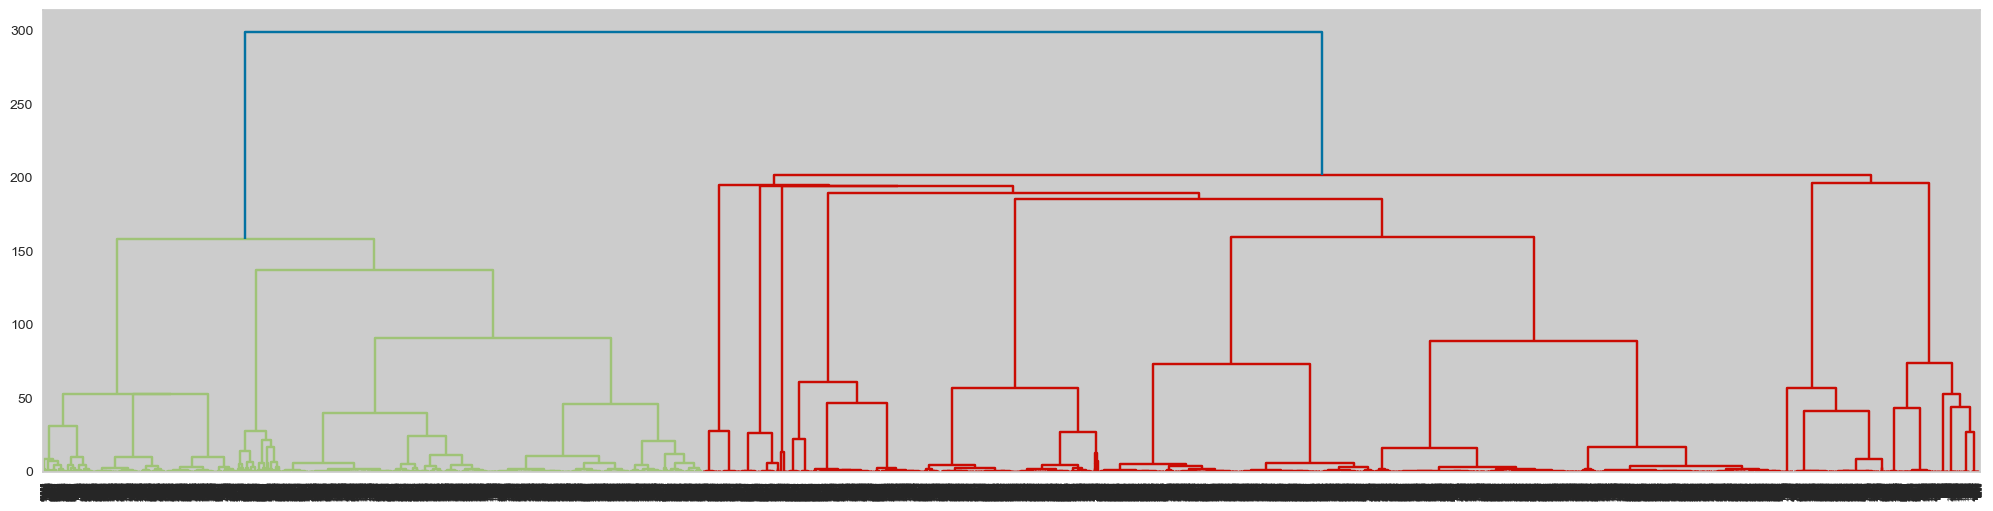

In [61]:
plt.figure(figsize=(25,6))
dendrogram(data);
plt.savefig('clustering.png', dpi=300)

### 2th Modell

In [62]:
flight_counts=(df.groupby('Operating Airline').size().reset_index(name='Flight_Count'))

In [63]:
flight_counts.head()

,Operating Airline,Flight_Count
0,ABC Aerolineas S.A. de C.V. dba Interjet,8
1,ATA Airlines,44
2,Aer Lingus,152
3,Aeromexico,234
4,Air Berlin,60


In [64]:
x2=flight_counts[['Flight_Count']]

In [65]:
x2=StandardScaler().fit_transform(x2)

In [66]:
km = KMeans(random_state=42)
visualizer = KElbowVisualizer(km, k=(2,10))

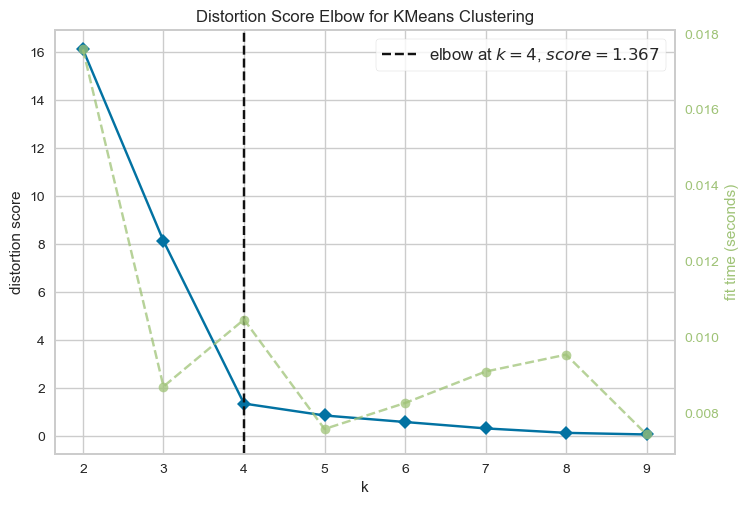

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [67]:
visualizer.fit(x2)
visualizer.show()

In [68]:
x2=StandardScaler().fit_transform(x2)

In [69]:
model=KMeans(4)

In [70]:
model=model.fit(x2)

In [71]:
tahmin2=model.predict(x2)

In [72]:
tahmin2

array([2, 2, 2, 0, 2, 0, 2, 0, 0, 2, 0, 2, 0, 3, 0, 2, 0, 2, 2, 0, 2, 2,
       2, 0, 2, 0, 0, 2, 2, 0, 0, 0, 0, 2, 2, 2, 2, 2, 0, 0, 2, 0, 2, 2,
       2, 2, 0, 2, 2, 0, 0, 0, 2, 0, 2, 2, 2, 2, 2, 0, 0, 0, 2, 2, 0, 3,
       0, 2, 0, 0, 0, 2, 2, 0, 1, 0, 0, 2, 2, 2, 2, 2, 2], dtype=int32)

In [73]:
flight_counts['Cluster2']=tahmin2

In [74]:
flight_counts['Cluster2'].value_counts()

Cluster2
2    45
0    35
3     2
1     1
Name: count, dtype: int64

In [75]:
silhouette_score(x2,tahmin2)

0.7541859349930917

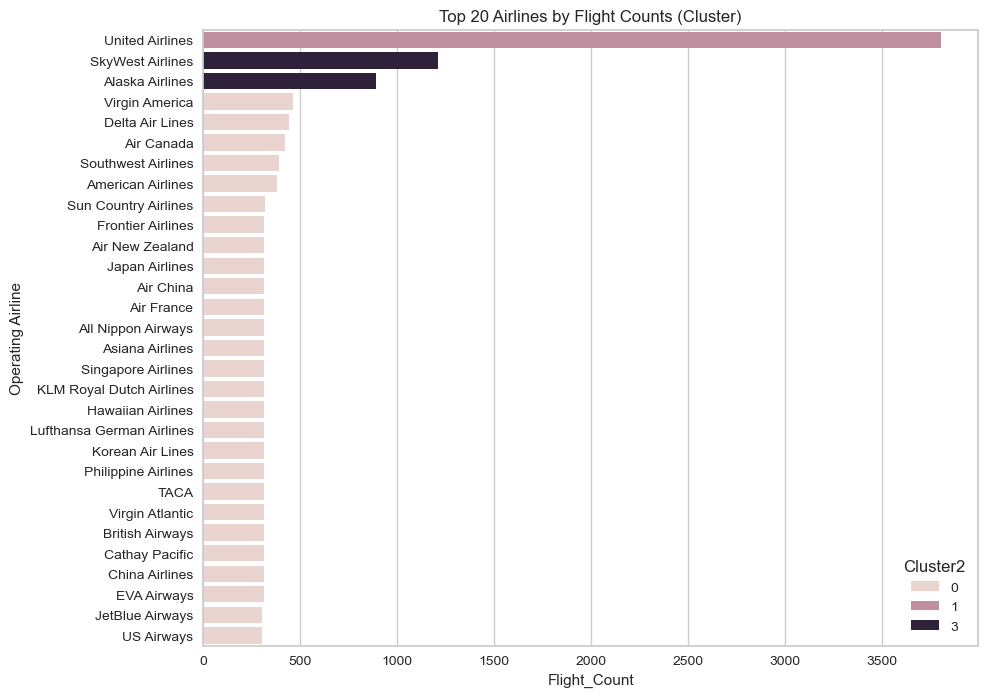

In [76]:
top20 = flight_counts.sort_values('Flight_Count', ascending=False).head(30)

plt.figure(figsize=(10,8))
sns.barplot(
    data=top20,
    x='Flight_Count',
    y='Operating Airline',
    hue='Cluster2',
    dodge=False
)
plt.title('Top 20 Airlines by Flight Counts (Cluster)')
plt.show()

### 3th Modell

In [77]:
passenger_counts=(df.groupby('Operating Airline')['Passenger Count'].sum().reset_index(name='Total_Passengers'))

In [78]:
x3=passenger_counts[['Total_Passengers']]

In [79]:
x3=StandardScaler().fit_transform(x3)

In [80]:
km=KMeans(random_state=42)
visualizer=KElbowVisualizer(km, k=(2,10))

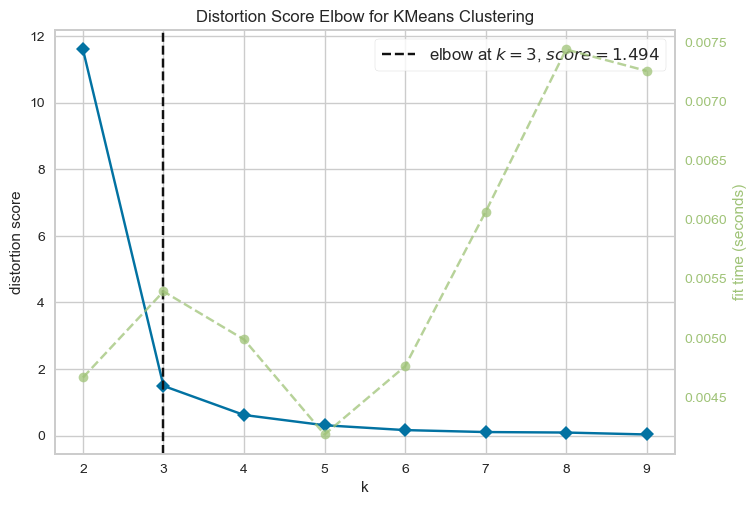

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [81]:
visualizer.fit(x3)
visualizer.show()

In [82]:
model=KMeans(3)

In [83]:
model=model.fit(x3)

In [84]:
tahmin3=model.predict(x3)

In [85]:
tahmin3

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0,
       0, 1, 1, 1, 1, 1, 1, 1, 2, 0, 1, 1, 1, 1, 1, 1, 1], dtype=int32)

In [86]:
passenger_counts['Cluster3']=tahmin3

In [87]:
passenger_counts['Cluster3'].value_counts()

Cluster3
1    77
0     5
2     1
Name: count, dtype: int64

In [88]:
df.head()

,Activity Period,Operating Airline,Operating Airline IATA Code,Published Airline,Published Airline IATA Code,GEO Summary,GEO Region,Activity Type Code,Price Category Code,Terminal,Boarding Area,Passenger Count,Year,Month,Cluster
0,200507,ATA Airlines,TZ,ATA Airlines,TZ,0,US,Deplaned,1,Terminal 1,B,27271,2005,7,2
1,200507,ATA Airlines,TZ,ATA Airlines,TZ,0,US,Enplaned,1,Terminal 1,B,29131,2005,7,2
2,200507,ATA Airlines,TZ,ATA Airlines,TZ,0,US,Thru / Transit,1,Terminal 1,B,5415,2005,7,2
3,200507,Air Canada,AC,Air Canada,AC,1,Canada,Deplaned,0,Terminal 1,B,35156,2005,7,1
4,200507,Air Canada,AC,Air Canada,AC,1,Canada,Enplaned,0,Terminal 1,B,34090,2005,7,3


In [89]:
silhouette_score(x3,tahmin3)

0.8983057527352664

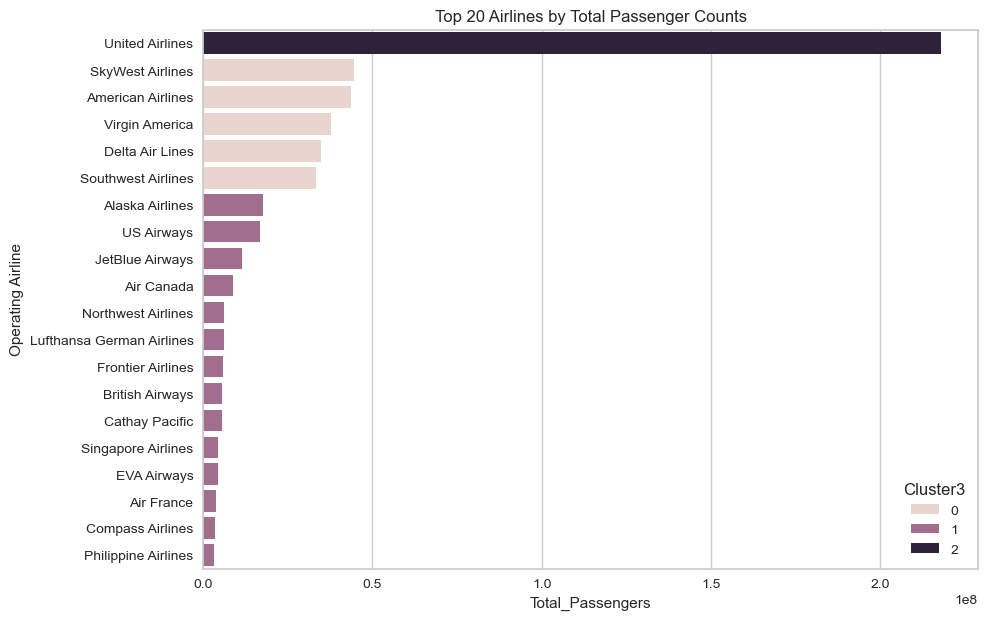

In [90]:
top20 = passenger_counts.sort_values('Total_Passengers', ascending=False).head(20)

plt.figure(figsize=(10,7))
sns.barplot(
    data=top20,
    x='Total_Passengers',
    y='Operating Airline',
    hue='Cluster3',
    dodge=False
)
plt.title('Top 20 Airlines by Total Passenger Counts')
plt.xlabel('Total_Passengers')
plt.ylabel('Operating Airline')
plt.show()

### Clustering Model Evaluation

Silhouette Scores measure how well observations fit within their assigned clusters. The three models use different features, so their scores should be interpreted separately.

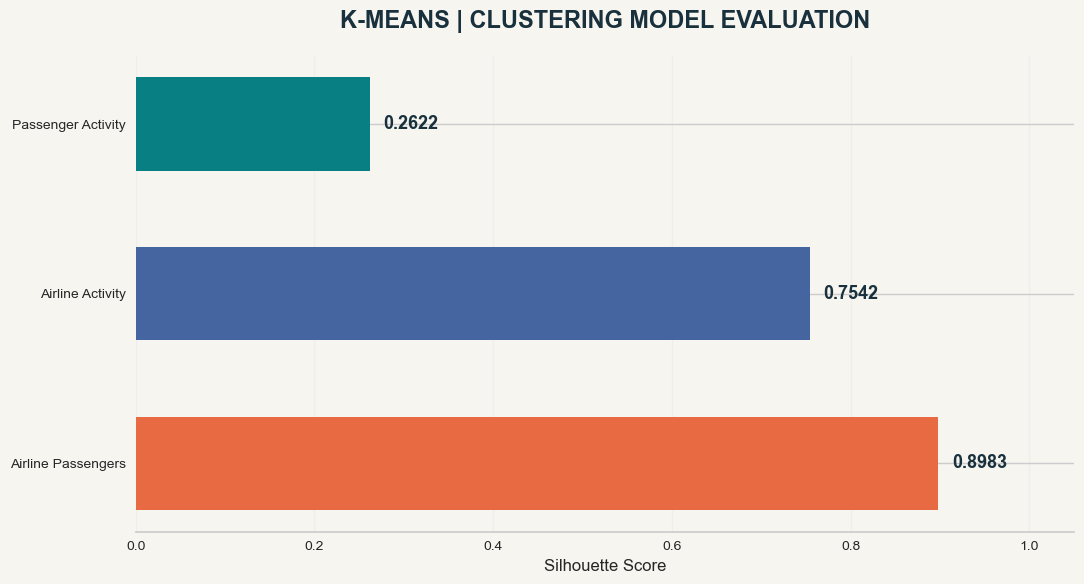

In [91]:
models = [
    'Passenger Activity',
    'Airline Activity',
    'Airline Passengers'
]

scores = [
    silhouette_score(x1, tahmin),
    silhouette_score(x2, tahmin2),
    silhouette_score(x3, tahmin3)
]

colors = ['#087F83', '#4565A0', '#E86A43']

fig, ax = plt.subplots(figsize=(11, 6), facecolor='#F7F5F0')
ax.set_facecolor('#F7F5F0')

bars = ax.barh(
    models,
    scores,
    color=colors,
    height=0.55
)

for bar, score in zip(bars, scores):
    ax.text(
        score + 0.015,
        bar.get_y() + bar.get_height() / 2,
        f'{score:.4f}',
        va='center',
        fontsize=13,
        fontweight='bold',
        color='#19313D'
    )

ax.set_title(
    'K-MEANS | CLUSTERING MODEL EVALUATION',
    fontsize=17,
    fontweight='bold',
    color='#19313D',
    pad=20
)

ax.set_xlabel('Silhouette Score', fontsize=12)
ax.set_xlim(0, 1.05)
ax.invert_yaxis()
ax.grid(axis='x', alpha=0.15)
ax.set_axisbelow(True)
ax.spines[['top', 'right', 'left']].set_visible(False)

plt.tight_layout()
plt.savefig(
    'images/clustering_model_comparison.png',
    dpi=300,
    bbox_inches='tight',
    facecolor=fig.get_facecolor()
)
plt.show()

## Conclusion

This project applied **K-Means Clustering** to explore passenger traffic and airline activity at San Francisco International Airport.

Three clustering models were developed with the following results:

- **Passenger Activity:** 4 clusters – Silhouette Score: 0.2414
- **Airline Activity:** 4 clusters – Silhouette Score: 0.7542
- **Airline Passengers:** 3 clusters – Silhouette Score: 0.8983

The results demonstrate how unsupervised machine learning can identify patterns in aviation data.

**Future improvements:** Explore alternative clustering algorithms and optimize feature selection.